# Lab 4: Data Visualization with Matplotlib & Seaborn

Welcome to Lab 4! So far you have learned to load, clean, and prepare data. But before you model anything, you need to *see* it. Numbers in a table rarely reveal patterns, outliers, or relationships on their own — visualizing the data is what makes them visible. This lab walks through creating and interpreting charts using Matplotlib and Seaborn, and introduces how visualization fits into Exploratory Data Analysis (EDA).

**After this lab you will be able to:**
- Create common Matplotlib plots (histograms, bar charts)
- Create statistical visualizations using Seaborn (count plots, box plots)
- Use a correlation heatmap to explore relationships between variables (EDA)
- Draw basic insights directly from a chart

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.
- Compare your output with the **Expected Output** shown below each exercise where provided.

## Why Data Visualization Matters

A dataset's distribution, outliers, and the relationships between its variables are often invisible in a plain table but become clear almost immediately once visualized. This is why visualization is one of the very first steps in any real-world data or ML project.

The chart types you will use most often are:

- **Histograms** — show the distribution of a single numeric variable (e.g., how ages are spread out).
- **Bar / Count plots** — show the frequency of categories (e.g., how many passengers were in each class).
- **Box plots** — show the spread of a numeric variable across groups, and flag outliers.
- **Heatmaps** — show how strongly numeric variables are related to one another.

We will create each of these, one at a time, using the dataset below.

## Loading the Dataset

For this lab, we will use the well-known **Titanic dataset**, which contains information about passengers aboard the Titanic (age, sex, passenger class, fare, survival status, and more). It has a good mix of numeric and categorical columns, which makes it ideal for practicing visualization.

The dataset is loaded directly from a public link below — no manual download is needed.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()   # click the button that appears and select titanic.csv
df = pd.read_csv('titanic.csv')
df.head(10)

Saving titanic.csv to titanic (1).csv


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


## Step 1 — Inspecting the Data

Before choosing which chart to use, you need to know whether a column is numeric or categorical — this determines which plot type actually makes sense for it.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Exercise:** Using `df.select_dtypes()`, store the list of numeric column names in `numeric_cols`, and the list of categorical (object-type) column names in `categorical_cols`.

In [5]:
numeric_cols = None
categorical_cols = None

### YOUR CODE HERE ###
numeric_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()
### END ###

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


**Expected Output (order may vary):**
```
Numeric columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
```

## Step 2 — Matplotlib: Histogram

A histogram shows how a numeric column's values are distributed across a range.

**Exercise:** Using `plt.hist()`, plot a histogram of the `Age` column (drop missing values first using `.dropna()`). Use 20 bins, and add a title, x-label ("Age"), and y-label ("Frequency").

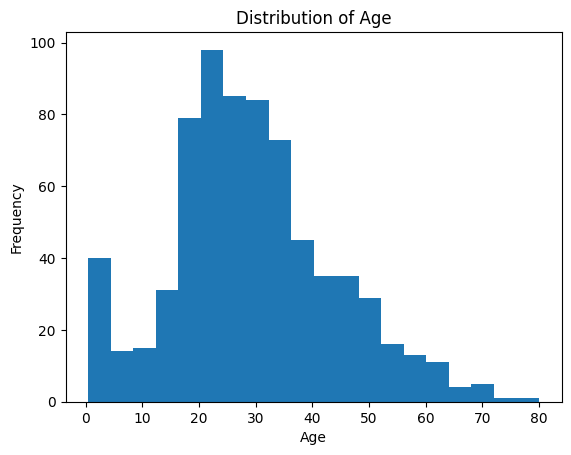

In [6]:
### YOUR CODE HERE ###
plt.hist(df['Age'].dropna(), bins=20)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()
### END ###

plt.show()

## Step 3 — Matplotlib: Bar Chart

**Exercise:** Create a bar chart showing how many passengers were in each passenger class (`Pclass`).

- Hint: use `df['Pclass'].value_counts()` to get the counts, then plot them with `plt.bar()`
- Add a title and axis labels

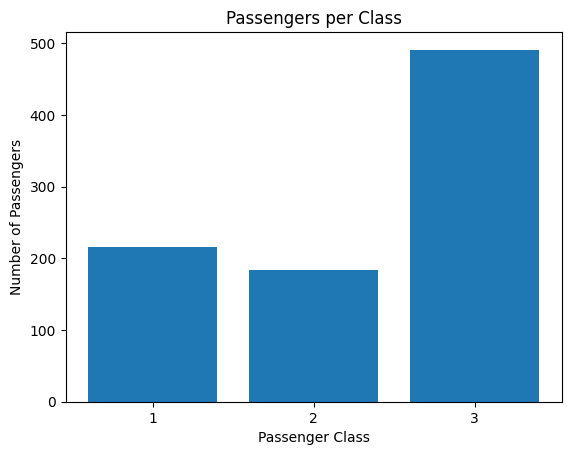

In [7]:
### YOUR CODE HERE ###
class_counts = df['Pclass'].value_counts().sort_index()

plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title('Passengers per Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.show()
### END ###

plt.show()

## Step 4 — Seaborn: Count Plot

Seaborn is built on top of Matplotlib and is designed specifically for statistical visualization — it usually needs less code and works directly with a DataFrame. The example below recreates the Step 3 chart using `sns.countplot()`. Run it and compare how much shorter the code is.

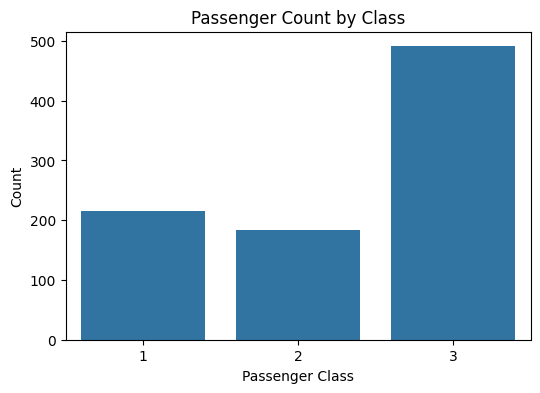

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Pclass', data=df)
plt.title('Passenger Count by Class')
plt.xlabel('Passenger Class')
plt.ylabel('Count')
plt.show()

## Step 5 — Seaborn: Box Plot

A box plot shows the spread of a numeric variable across different groups, and makes outliers immediately visible as individual points beyond the whiskers.

**Exercise:** Create a box plot showing the `Fare` distribution across the three passenger classes (`Pclass`), using `sns.boxplot(x='Pclass', y='Fare', data=df)`.

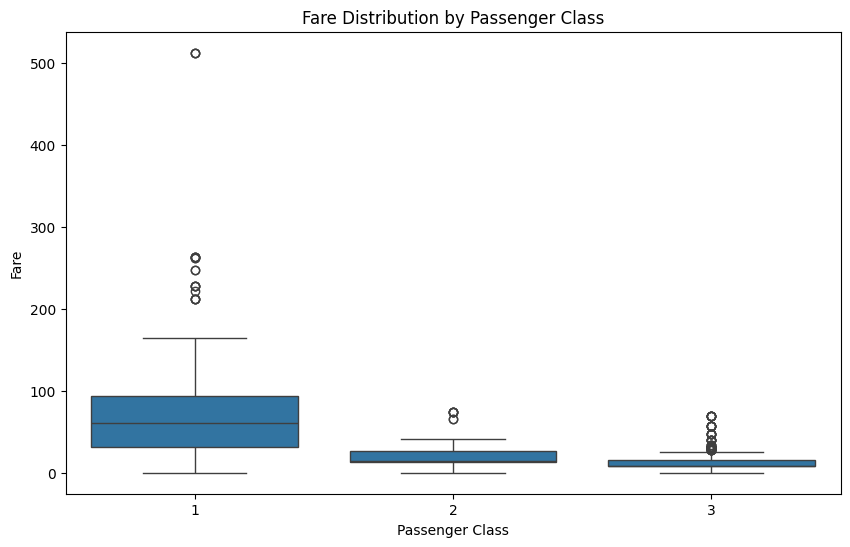

In [12]:
### YOUR CODE HERE ###
plt.figure(figsize=(10, 6))
sns.boxplot(x='Pclass', y='Fare', data=df)
plt.title('Fare Distribution by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.show()
### END ###

plt.show()

## Step 6 — EDA: Correlation Heatmap

**Exploratory Data Analysis (EDA)** is the process of examining a dataset before modeling it, in order to understand its structure and spot patterns. A correlation heatmap is one of the most common EDA tools — it instantly reveals which numeric variables move together, something that is difficult to notice from raw numbers alone.

**Exercise:** Using `df.corr(numeric_only=True)` together with `sns.heatmap()`, create a correlation heatmap of the numeric columns. Set `annot=True` so the correlation values are visible on the chart.

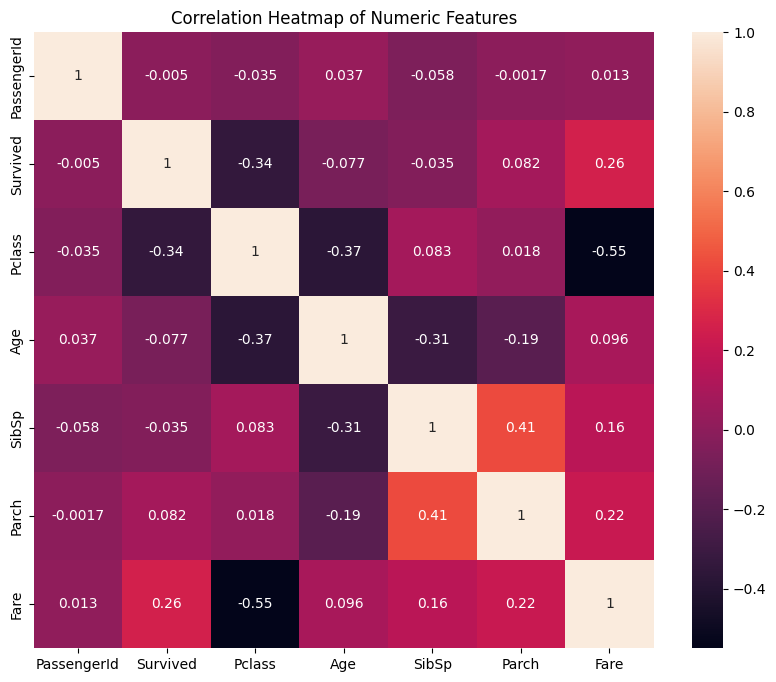

In [13]:
### YOUR CODE HERE ###
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()
### END ###

plt.show()

**What to remember from this lab:**
- Check whether a column is numeric or categorical before choosing a chart type
- Histograms show distribution; bar/count plots show frequency; box plots show spread and outliers; heatmaps show relationships
- Seaborn is built on Matplotlib and usually needs less code for the same result
- A correlation heatmap is one of the most common tools used during EDA

## Lab Tasks

Complete the following tasks in this notebook, below this cell, using `df`.

1. **Full Visualization Recap:** In a markdown cell, write 3–4 sentences summarizing, in your own words, which chart types you used in this lab and what each one is best suited for.
2. **Age Distribution by Survival:** Create a plot (histogram or box plot) comparing the `Age` distribution between passengers who survived (`Survived == 1`) and those who did not (`Survived == 0`).
3. **Exploring Relationships:** Create a scatter plot of `Age` (x-axis) vs. `Fare` (y-axis), with points colored by `Survived` (hint: `sns.scatterplot(x='Age', y='Fare', hue='Survived', data=df)`).
4. **Survival Summary:** Using `df`, compute the average `Survived` rate and passenger count per `Pclass` and `Sex`, in a single `.groupby().agg()` call.
5. **Reflection:** In a markdown cell, note which chart in this lab you found most useful for revealing a pattern, and why.

## Visualization Recap

In this lab I used a histogram, a bar chart, a box plot, and a correlation heatmap. The **histogram** of `Age` is best for seeing how a single numeric variable is distributed, while the **bar chart** of `Pclass` is best for comparing counts across categories. The **box plot** of `Fare` by `Pclass` compares a numeric variable across groups, showing medians, spread, and outliers at once. The **heatmap** summarizes the relationships between all numeric columns in one view, which helps spot which variables move together.

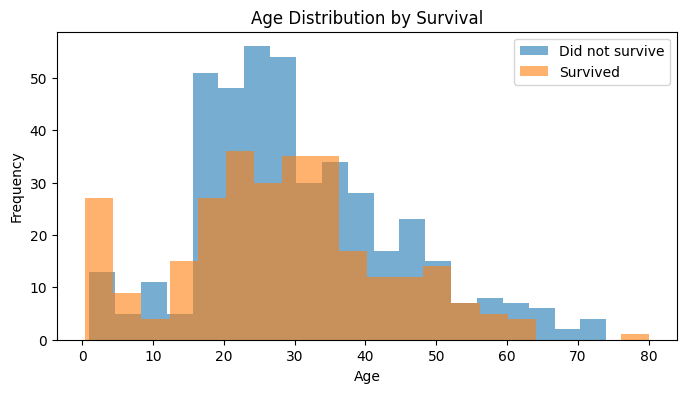

In [17]:
# Task 2
plt.figure(figsize=(8, 4))
plt.hist(df[df['Survived'] == 0]['Age'].dropna(), bins=20, alpha=0.6, label='Did not survive')
plt.hist(df[df['Survived'] == 1]['Age'].dropna(), bins=20, alpha=0.6, label='Survived')
plt.title('Age Distribution by Survival')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

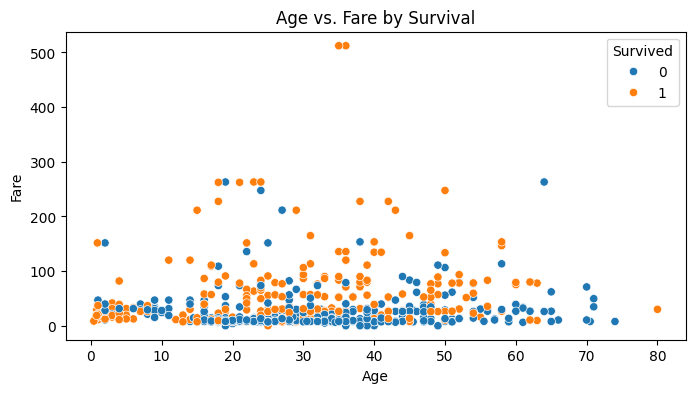

In [18]:
# Task 3
plt.figure(figsize=(8, 4))
sns.scatterplot(x='Age', y='Fare', hue='Survived', data=df)
plt.title('Age vs. Fare by Survival')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

In [19]:
# Task 4
survival_summary = df.groupby(['Pclass', 'Sex']).agg(
    survival_rate=('Survived', 'mean'),
    passenger_count=('Survived', 'count')
)

print(survival_summary)

               survival_rate  passenger_count
Pclass Sex                                   
1      female       0.968085               94
       male         0.368852              122
2      female       0.921053               76
       male         0.157407              108
3      female       0.500000              144
       male         0.135447              347


_Write your Task 5 reflection here._
## Reflection

The chart I found most useful for revealing a pattern was the **box plot of `Fare` by `Pclass`**. It showed right away that fares drop sharply from first to third class, and it also revealed the wide spread and extreme outliers in first class, which a simple average would have hidden. It let me compare three groups on one numeric variable at a glance, making the link between class and ticket price much clearer than the raw numbers.
